<a href="https://colab.research.google.com/github/igornvidal/apollo_analytics_academy/blob/main/TME_Callcenter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

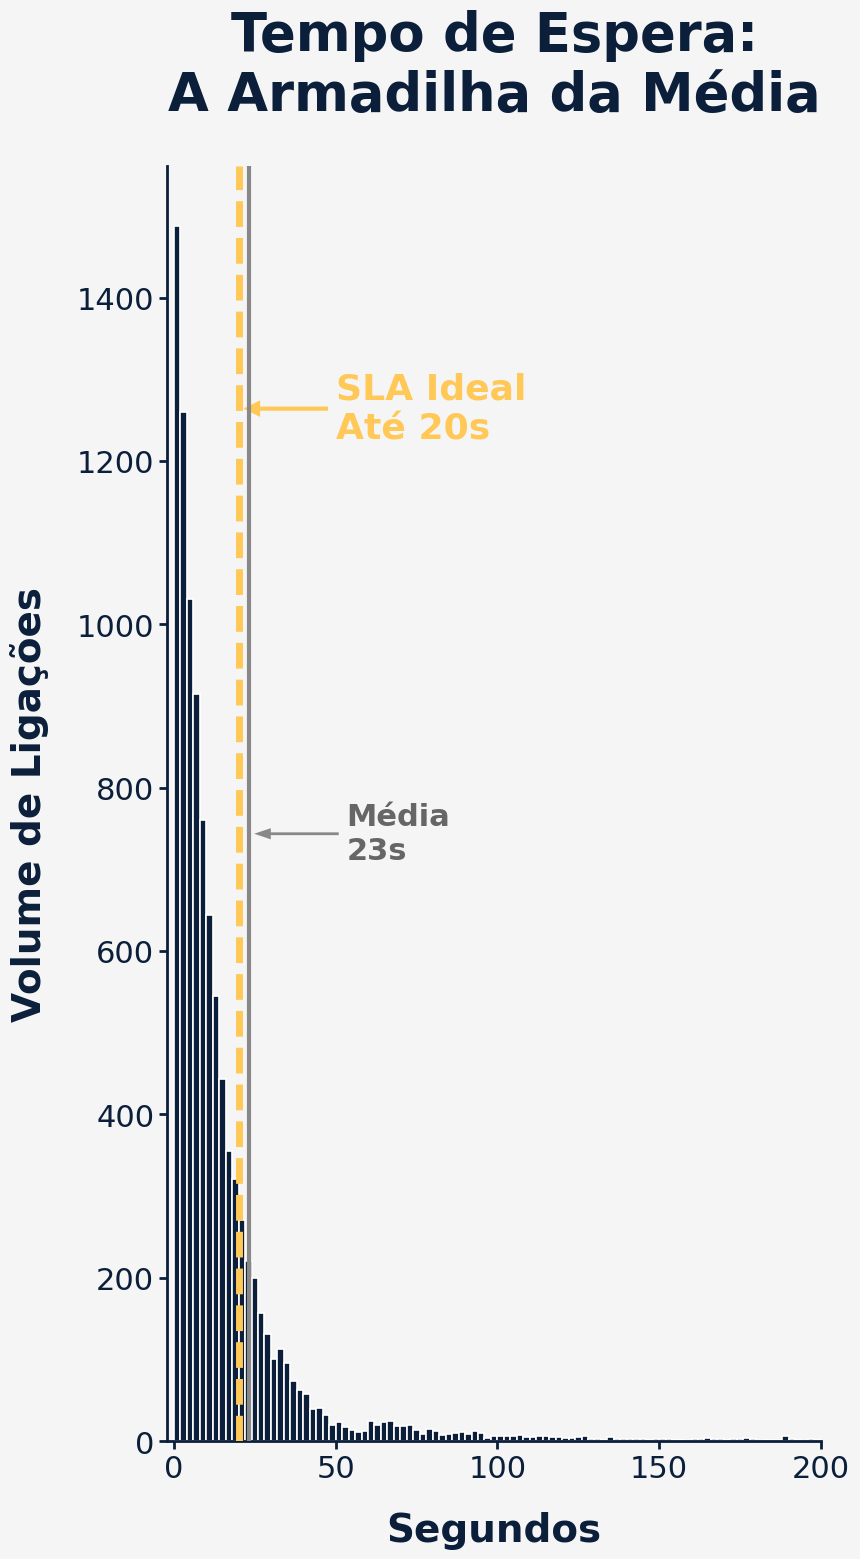

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Simulação do Dataset (Garante que os dados estejam disponíveis ao rodar)
np.random.seed(42)
baseline = np.random.exponential(scale=12, size=9500)
outliers = (np.random.pareto(1.1, 500) + 1) * 60
tempos = np.concatenate([baseline, outliers])
np.random.shuffle(tempos)
tempos = np.clip(tempos, 0, 3600)
df = pd.DataFrame({'tempo_espera_segundos': tempos})
media = df['tempo_espera_segundos'].mean()

# 2. Paleta Oficial Apollo Analytics Academy
bg_color = '#F5F5F5'        # Cinza claro (fundo secundário)
apollo_blue = '#0B1F3B'     # Azul escuro (principal)
apollo_gold = '#FFC857'     # Dourado (acento)

# Ajuste global para garantir legibilidade no mobile
plt.rcParams.update({'font.size': 20})

# 3. Criação do Gráfico (Proporção 9:16)
fig, ax = plt.subplots(figsize=(9, 16), facecolor=bg_color)
ax.set_facecolor(bg_color)

# Plot do Histograma (Calcula sobre todos os dados para não perder os outliers no volume)
n, bins, patches = ax.hist(df['tempo_espera_segundos'], bins=200, range=(0, 400),
                           color=apollo_blue, edgecolor='white', linewidth=1.2)

# Linha de SLA (Destaque em Dourado)
ax.axvline(20, color=apollo_gold, linestyle='--', linewidth=5, zorder=5)
ax.annotate('SLA Ideal\nAté 20s', xy=(20, max(n)*0.85), xytext=(50, max(n)*0.85),
            arrowprops=dict(facecolor=apollo_gold, shrink=0.05, width=3, headwidth=12, edgecolor='none'),
            fontsize=26, color=apollo_gold, fontweight='bold', va='center')

# Linha da Média (Secundária)
ax.axvline(media, color='#888888', linestyle='-', linewidth=3, zorder=4)
ax.annotate(f'Média\n{media:.0f}s', xy=(media, max(n)*0.5), xytext=(media+30, max(n)*0.5),
            arrowprops=dict(facecolor='#888888', shrink=0.05, width=2, headwidth=8, edgecolor='none'),
            fontsize=22, color='#666666', fontweight='bold', va='center')

# Cortando o eixo X no 200 conforme solicitado
ax.set_xlim(-2, 200)

# Textos e Títulos adaptados para Reels
ax.set_title("Tempo de Espera:\nA Armadilha da Média", loc='center',
             fontsize=38, fontweight='bold', color=apollo_blue, pad=40)
ax.set_xlabel("Segundos", fontsize=28, fontweight='bold', color=apollo_blue, labelpad=20)
ax.set_ylabel("Volume de Ligações", fontsize=28, fontweight='bold', color=apollo_blue, labelpad=20)

# Limpeza e Estilização dos Eixos
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color(apollo_blue)
ax.spines['bottom'].set_color(apollo_blue)
ax.spines['left'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)
ax.tick_params(colors=apollo_blue, labelsize=22, width=2, length=6)

plt.tight_layout()

# Salva a imagem em alta resolução e exibe
plt.savefig('grafico_apollo_reels.png', format='png', dpi=300, facecolor=bg_color)
plt.show()